# JS14 – Convolutional Neural Network (CNN)
## Penerapan Arsitektur Convolutional Neural Network (1D-CNN) pada Dataset Burnout

---

### Deskripsi & Tujuan
Pada modul **JS14**, mahasiswa mendalami arsitektur **Convolutional Neural Network (CNN)** yang memanfaatkan operasi konvolusi (`Conv2D`/`Conv1D`) dan pooling (`MaxPooling`) untuk mengekstraksi representasi fitur secara hierarkis.

Meskipun CNN utamanya digunakan pada data citra 2D (seperti pada Praktikum 1 Cat vs Dog dan Praktikum 2 CIFAR-10), prinsip konvolusi 1 dimensi (**1D-CNN**) dapat diadaptasi untuk mengekstraksi korelasi lokal pada data terstruktur/tabular berdimensi tinggi:
1. Mengubah representasi fitur tabular (109 fitur) menjadi 3D Tensor `(Batch_Size, 109, 1)`.
2. Menerapkan layer `Conv1D`, `BatchNormalization`, `MaxPooling1D`, `Dropout`, dan dense classification layer.
3. Mengevaluasi performa model dan melakukan analisis komparatif mendalam mengenai karakteristik 1D-CNN pada data tabular versus ANN MLP konvensional.


### 1. Import Library & Persiapan Data

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42)
np.random.seed(42)

# Load dan Preprocessing
df = pd.read_csv('burnout_dataset1.csv')
df_clean = df.dropna(subset=['Burnout_Risk']).copy()

X = df_clean.drop(columns=['Person_ID', 'Burnout_Risk', 'Burnout_Score', 'AI_Wellness_Recommendation'])
risk_map = {'Low': 0, 'Moderate': 1, 'High': 2}
y = df_clean['Burnout_Risk'].map(risk_map).values
target_names = ['Low', 'Moderate', 'High']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])

X_processed = preprocessor.fit_transform(X)
feature_dim = X_processed.shape[1]

# Split 70% Train, 15% Val, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(X_processed, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

y_train_cat = to_categorical(y_train, 3)
y_val_cat   = to_categorical(y_val, 3)
y_test_cat  = to_categorical(y_test, 3)

# Reshape input tabular menjadi 3D Tensor untuk Conv1D: (N, feature_dim, 1)
X_train_cnn = X_train.reshape((X_train.shape[0], feature_dim, 1))
X_val_cnn   = X_val.reshape((X_val.shape[0], feature_dim, 1))
X_test_cnn  = X_test.reshape((X_test.shape[0], feature_dim, 1))

print(f"Bentuk Input Tensor 1D-CNN: {X_train_cnn.shape}")


Bentuk Input Tensor 1D-CNN: (6610, 109, 1)


### 2. Membangun Arsitektur Model 1D-CNN
Arsitektur terdiri dari:
- **Input Layer**: `(109, 1)`
- **Blok Konvolusi 1**: `Conv1D(64, kernel_size=3)` + `BatchNormalization` + `MaxPooling1D(2)` + `Dropout(0.2)`
- **Blok Konvolusi 2**: `Conv1D(128, kernel_size=3)` + `BatchNormalization` + `MaxPooling1D(2)` + `Dropout(0.3)`
- **Dense Classifier**: `Flatten` + `Dense(64, relu)` + `BatchNormalization` + `Dropout(0.3)` + `Dense(3, softmax)`


In [2]:
model_cnn1d = models.Sequential([
    layers.Input(shape=(feature_dim, 1)),
    
    # Blok Konvolusi 1
    layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.2),

    # Blok Konvolusi 2
    layers.Conv1D(filters=128, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.3),

    # Classifier
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax', name='cnn_burnout_output')
])

model_cnn1d.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn1d.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 109, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 109, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 54, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 54, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 54, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 54, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 27, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 27, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3456)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       221,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_burnout_output (Dense)      │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 247,427 (966.51 KB)

 Trainable params: 246,915 (964.51 KB)

 Non-trainable params: 512 (2.00 KB)

### 3. Pelatihan & Evaluasi Model 1D-CNN

In [3]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

t0 = time.time()
history_cnn = model_cnn1d.fit(
    X_train_cnn, y_train_cat,
    validation_data=(X_val_cnn, y_val_cat),
    epochs=40,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)
time_cnn = time.time() - t0

# Evaluasi pada Data Uji
test_loss_cnn, test_acc_cnn = model_cnn1d.evaluate(X_test_cnn, y_test_cat, verbose=0)
y_pred_probs_cnn = model_cnn1d.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)

f1_macro_cnn = f1_score(y_test, y_pred_cnn, average='macro')
print(f"\n=== HASIL EVALUASI 1D-CNN CLASSIFIER ===")
print(f"Akurasi Test  : {test_acc_cnn * 100:.2f}%")
print(f"Macro F1-Score: {f1_macro_cnn:.4f}")
print(f"Loss Test     : {test_loss_cnn:.4f}")
print(f"Waktu Training: {time_cnn:.2f} detik")


Epoch 1/40


  1/104 ━━━━━━━━━━━━━━━━━━━━ 3:57 2s/step - accuracy: 0.3281 - loss: 1.6902

  3/104 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.3602 - loss: 1.7075

  5/104 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.3932 - loss: 1.6154

  8/104 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.4324 - loss: 1.5053

 11/104 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.4683 - loss: 1.4063

... (510 outputs left out)

 97/104 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9868 - loss: 0.0361

100/104 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9869 - loss: 0.0359

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9891 - loss: 0.0301 - val_accuracy: 0.9880 - val_loss: 0.0450



=== HASIL EVALUASI 1D-CNN CLASSIFIER ===
Akurasi Test  : 98.87%
Macro F1-Score: 0.9842
Loss Test     : 0.0445
Waktu Training: 33.38 detik


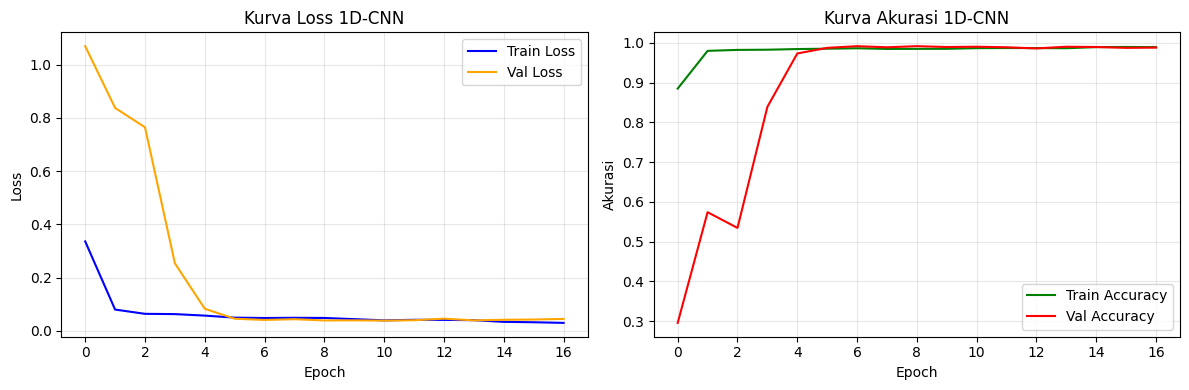

=== Classification Report 1D-CNN ===
              precision    recall  f1-score   support

         Low     1.0000    1.0000    1.0000       718
    Moderate     0.9975    0.9642    0.9806       419
        High     0.9490    0.9964    0.9721       280

    accuracy                         0.9887      1417
   macro avg     0.9822    0.9869    0.9842      1417
weighted avg     0.9892    0.9887    0.9888      1417



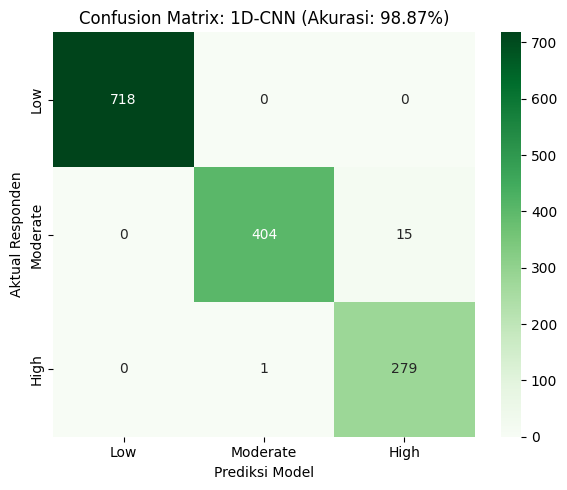

In [4]:
# Visualisasi Kurva Loss & Akurasi
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['loss'], label='Train Loss', color='blue')
plt.plot(history_cnn.history['val_loss'], label='Val Loss', color='orange')
plt.title('Kurva Loss 1D-CNN')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['accuracy'], label='Train Accuracy', color='green')
plt.plot(history_cnn.history['val_accuracy'], label='Val Accuracy', color='red')
plt.title('Kurva Akurasi 1D-CNN')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Classification Report & Confusion Matrix Heatmap
print("=== Classification Report 1D-CNN ===")
print(classification_report(y_test, y_pred_cnn, target_names=target_names, digits=4))

cm_cnn = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens',
            xticklabels=target_names, yticklabels=target_names)
plt.title(f'Confusion Matrix: 1D-CNN (Akurasi: {test_acc_cnn * 100:.2f}%)')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual Responden')
plt.tight_layout()
plt.show()


### 4. Pembahasan Karakteristik 1D-CNN vs MLP pada Data Tabular
1. **Asumsi Spasial / Korelasi Lokal pada CNN**:
   - Lapisan konvolusi (`Conv1D`/`Conv2D`) bekerja berdasarkan asumsi kuat bahwa **nilai-nilai yang berdekatan memiliki hubungan lokal yang erat** (*spatial / temporal locality*), seperti piksel bersebelahan pada foto kucing/anjing (JS14 Praktikum 1) atau CIFAR-10 (JS14 Praktikum 2).
   - Pada data tabular, urutan kolom bersifat arbitrer (*permutation invariant*). Kolom `Age` bersebelahan dengan `Monthly_Income_USD` hanya karena urutan pembacaan CSV, bukan karena dependensi spasial fisik.
2. **Implikasi Empiris**:
   - Oleh sebab itu, ANN MLP (JS13) dengan koneksi penuh (*fully-connected layers*) secara alami lebih fleksibel dalam menangkap korelasi antar-fitur non-lokal pada dataset tabular, sedangkan 1D-CNN (JS14) membutuhkan pertimbangan pengelompokan fitur (*feature grouping*) agar operasi konvolusi lokal dapat bekerja maksimal.
